::: {.content-visible when-format="html"}
::: {.case-links}
[<i class="bi bi-journal-text"></i> Appendix](03_reproduce_body_triage.ipynb){.btn .btn-outline-secondary .btn-sm}
[<i class="bi bi-sliders"></i> Explorer](../explorer/triage.qmd){.btn .btn-outline-secondary .btn-sm}
[<i class="bi bi-file-earmark-pdf"></i> PDF](04_body_triage_case_study.pdf){.btn .btn-outline-secondary .btn-sm}
[<i class="bi bi-github"></i> Code](https://github.com/matheusmmmp/digilab-reward-case-study){.btn .btn-outline-secondary .btn-sm}
[<i class="bi bi-table"></i> Data](../data/SCHEMA.md){.btn .btn-outline-secondary .btn-sm}
[<i class="bi bi-quote"></i> Cite](../index.qmd#cite){.btn .btn-outline-secondary .btn-sm}
:::
:::

In [1]:
#| label: setup
#| code-summary: "Setup: imports, data, shared helpers, every official estimate"
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

from casestudy import style
from casestudy import triage as tr

style.apply()
REF = tr.REF
C4 = REF["c4_quoted"]["values"]  # quoted from the official result; no C4 per-life data is used
CHECKS = []  # every official number shown below is asserted and logged here


def check(got, ref, what):
    tr.assert_matches(got, ref, what)
    CHECKS.append(what)


def say(text):
    display(Markdown(text))


def show(df):
    display(HTML(df.to_html(index=False, border=0, classes="table table-sm")))


E = {}
for name, ref in REF["estimates"].items():
    E[name] = tr.estimate(*tr.split(name))
    check(E[name], ref, name)
assert REF["formal_reading"] is False
q = lambda r: tr.fmt(r)  # "+0.024 [+0.009; +0.038]"
t12, c12 = E["time_well|12_cells"], C4["time_well|12_cells"]
assert c12["mean"] / t12["mean"] > 2  # "less than half"

In [2]:
#| label: in-short
say(f'''**In short.** A variant of the pet's body physiology had passed a pre-registered validation of
{REF["c4_quoted"]["units"]} units on an earlier version of the pet: the share of the pet's life spent "well"
(neither deprived nor exhausted) rose by **{q(c12)}**. The pet changed after that, so I re-measured the same
change on the current pet, starting with a cheap triage of {REF["units"]} units (a unit is one random seed,
run once in each arm and in each of the 12 cells, the owner-type × food-place combinations). The triage gives **{q(t12)}**:
less than half.

Three things to keep in mind. The triage was planned to **estimate the size of the effect only: it has no formal
reading** (no "confirms" or "does not confirm", and no cut was applied). The two numbers come from **different pets
and different seeds, so the pair is not a contrast**: it is shown side by side, never subtracted. And the reasons given below for why it shrank are not an explanation: they are what the official result describes
alongside the estimates, without a reading (the current pet already starts higher, it has little exhaustion, and near
the feeder the measure has almost no room left), and the same points the plan wrote down for its prediction before
the triage; the triage does not test them. After the triage I closed the question without the planned {tr.N_UNITS_PLANNED}-unit run.

Every number on this page is recomputed in a code cell from the published data
(`data/body_triage_lives.parquet`) and asserted against the official values (`data/body_triage_reference.json`)
to within 1e-9, or read from that file. [Code is folded; click "Code" to see it.]{{.content-visible when-format="html"}}[The code is not shown in this PDF; it is on the site and in the repository.]{{.content-visible unless-format="html"}}''')

**In short.** A variant of the pet's body physiology had passed a pre-registered validation of
200 units on an earlier version of the pet: the share of the pet's life spent "well"
(neither deprived nor exhausted) rose by **+0.062 [+0.058; +0.067]**. The pet changed after that, so I re-measured the same
change on the current pet, starting with a cheap triage of 20 units (a unit is one random seed,
run once in each arm and in each of the 12 cells, the owner-type × food-place combinations). The triage gives **+0.024 [+0.009; +0.038]**:
less than half.

Three things to keep in mind. The triage was planned to **estimate the size of the effect only: it has no formal
reading** (no "confirms" or "does not confirm", and no cut was applied). The two numbers come from **different pets
and different seeds, so the pair is not a contrast**: it is shown side by side, never subtracted. And the reasons given below for why it shrank are not an explanation: they are what the official result describes
alongside the estimates, without a reading (the current pet already starts higher, it has little exhaustion, and near
the feeder the measure has almost no room left), and the same points the plan wrote down for its prediction before
the triage; the triage does not test them. After the triage I closed the question without the planned 200-unit run.

Every number on this page is recomputed in a code cell from the published data
(`data/body_triage_lives.parquet`) and asserted against the official values (`data/body_triage_reference.json`)
to within 1e-9, or read from that file. [Code is folded; click "Code" to see it.]{.content-visible when-format="html"}[The code is not shown in this PDF; it is on the site and in the repository.]{.content-visible unless-format="html"}

## 1. The question

The pet is a small simulated animal. Its body has a simple physiology: food, hygiene and energy run down over the day and are restored by eating, being cleaned and sleeping. The project's welfare measure, **time well**, is the fraction of the pet's decisions taken while it was neither *deprived* (food, hygiene or energy below a fixed threshold) nor *exhausted* (energy below another fixed threshold).

An earlier study had tested **a variant of the pet's body physiology** (on this page it is only "the body variant") and found that it raised time well. That study used an earlier version of the pet, the one kept on the research bench. The current pet, the one in the game, has mechanics the bench pet lacks; one of them changes how tired the pet gets, and according to the analysis plan most of the earlier gain came from less exhaustion.

So the plan asked, in plain words: **on the current pet, does the body variant still make the pet spend more time well, without costing it health or its ability to find food?**

## 2. Two measurements, not a contrast

"C4" is the project's label for the earlier study; it is kept here because the official result uses it.

| | earlier study ("C4") | this triage |
|---|---|---|
| pet | the earlier, research-bench version | the current version, as simulated in the research code |
| units | 200 | 20 |
| seeds | its own reserved range | a different reserved range |
| reading | a pre-registered rule, applied: it passed, with a caveat on one cell | **none**: estimates only |

The two studies use the same arms, the same 12 cells, the same analysis and the same measure. But the pet is different and so are the random seeds, so **the difference between the two estimates is not an estimate of anything**: no interval exists for it and none is computed. The earlier study's numbers enter this page only as values quoted from the comparison section of the triage's official result; no per-life data of the earlier study is used.

## 3. The design of the triage

Two **arms**: `control` (the current pet as it is) and `body_variant` (the same pet with the body variant). Four simulated **owner types**: `attentive`, `neglectful`, `random`, `inconsistent`; `neglectful` and `random` are the two that let the food run out. Three **places** where the owner puts the food:

- `at_feeder`: at the pet's feeder, always the same spot.
- `far`: far from the pet, at a direction and distance drawn anew at every feeding.
- `far_fixed`: each life draws three fixed spots far from the feeder once, at the start; every feeding lands on one of the three at random. The food is far, but where it appears is regular, so the pet can learn it.

The 4 × 3 owner/place combinations are the 12 **cells**. A **unit** is one random seed, given to both arms in every cell, so every comparison is paired. Each life lasts 14 simulated days.

**Analysis** (the plan's, unchanged): for each unit, take `body_variant − control` in each cell and average over the cells; the estimate is the mean of the unit numbers and the 95% interval is Student t over the units. It is reported over the 12 cells and over the **11 distinct cells**: (`inconsistent`, `at_feeder`) comes out identical to (`attentive`, `at_feeder`) in every life, so it counts the same cell twice.

**What a triage is here.** The plan had a confirmatory run of 200 units with a pre-registered reading rule. Before that run, a decision paused the project's confirmatory runs on the pet's brain: every idea there first gets a triage of 10–20 units, *only to estimate the size of the effect*. This study is about the body, not the brain; I chose separately to give it a triage first too. The addendum that set up this triage was written and approved before it ran, and it states that the triage gives no class, no p-value, no "confirms" or "does not confirm", and that no cut is applied to it.

In [3]:
#| label: timeline
#| code-summary: "Timeline from the commit history and the run's metadata"
timeline = pd.DataFrame([
    ("11-20 14:04", "Earlier study (C4) result committed", "4e5f4f64"),
    ("11-20 15:59", "Analysis plan proposed, with its prediction written down", "51f02fe9"),
    ("11-21 00:42", "Analysis plan approved", "3c223667"),
    ("11-21 00:54", "Simulation code merged", "bc0d3b43"),
    ("11-21 11:35", "Addendum proposed: a 20-unit triage first (and the code's triage mode)", "715f889c"),
    ("11-21 11:37", "Addendum approved", "d69a2500"),
    ("11-21 13:49:12", "Triage started", "e5d95bfc"),
    ("11-21 13:58:24", "Triage finished: all lives measured and saved", ""),
    ("11-21 14:01", "Triage result committed", "f5d6a7cd"),
    ("11-21 16:55", "Question closed without the 200-unit run", "23733ac3"),
], columns=["2026, UTC−3", "event", "commit"])
run = REF["run"]
assert ("2026-" + timeline.iloc[6, 0].replace(" ", "T"), "2026-" + timeline.iloc[7, 0].replace(" ", "T")) == (run["start"], run["end"])
show(timeline)
secs = run["duration_s"]
n_lives = int(tr.sql("SELECT count(*) AS n FROM triage").n[0])
say("Commit times are commit dates from the repository history (for `715f889c` the author date is earlier, "
    "11:21); the start and end of the triage come from the run's metadata file.\n\n"
    f"The triage ran once, {n_lives} lives with {run['processes']} processes, in **{int(secs // 60)} min "
    f"{int(secs % 60)} s** of wall time (the run's recorded duration), on the main branch as it was then (`e5d95bfc`), "
    "which carried the approved plan and addendum unchanged.")

"2026, UTC−3",event,commit
11-20 14:04,Earlier study (C4) result committed,4e5f4f64
11-20 15:59,"Analysis plan proposed, with its prediction written down",51f02fe9
11-21 00:42,Analysis plan approved,3c223667
11-21 00:54,Simulation code merged,bc0d3b43
11-21 11:35,Addendum proposed: a 20-unit triage first (and the code's triage mode),715f889c
11-21 11:37,Addendum approved,d69a2500
11-21 13:49:12,Triage started,e5d95bfc
11-21 13:58:24,Triage finished: all lives measured and saved,
11-21 14:01,Triage result committed,f5d6a7cd
11-21 16:55,Question closed without the 200-unit run,23733ac3


Commit times are commit dates from the repository history (for `715f889c` the author date is earlier, 11:21); the start and end of the triage come from the run's metadata file.

The triage ran once, 480 lives with 4 processes, in **9 min 11 s** of wall time (the run's recorded duration), on the main branch as it was then (`e5d95bfc`), which carried the approved plan and addendum unchanged.

The plan was written before any life of this study existed, but after a count made for it: 120 lives of the current pet (5 units, both arms, the 12 cells) run with the seeds reserved for software tests, which are not research data. From that count the plan predicted that the 200-unit run would read "does not confirm": the 5 units had suggested a gain smaller than the plan's margin. The 200-unit run never happened (section 8), so that prediction was never tested.

## 4. The data

One row per simulated life, 14 columns; the dictionary is on the [data schema](../data/SCHEMA.md#case-2) page. Only outcome measures are published; the body variant is not described beyond its name, and the pet's internal state is not published. The checks are plain DuckDB SQL over the parquet (the same run in `scripts/check_data.py`).

In [4]:
#| label: data-counts
#| code-summary: "DuckDB: counts, pairing and arm means"
per_arm = tr.sql("SELECT arm, count(*) AS lives, count(DISTINCT owner || place) AS cells, count(DISTINCT unit) AS units, "
                 "avg(time_well) AS time_well FROM triage GROUP BY arm ORDER BY arm DESC")
pairing = tr.sql("SELECT count(*) AS unit_cells, min(k) AS min_arms, max(k) AS max_arms FROM "
                 "(SELECT unit, owner, place, count(DISTINCT arm) AS k FROM triage GROUP BY ALL)")
assert n_lives == REF["lives"] == 480 and (per_arm.lives == 240).all()
assert (per_arm.cells == 12).all() and (per_arm.units == tr.N_UNITS).all()
assert pairing.unit_cells[0] == 240 and pairing.min_arms[0] == pairing.max_arms[0] == 2
for r in per_arm.itertuples():
    assert abs(r.time_well - REF["arm_means"][r.arm]["time_well"]) <= 1e-9
    CHECKS.append(f"arm mean {r.arm}")
show(per_arm.round(3))
say(f"**{n_lives} lives** = {len(per_arm)} arms × {per_arm.cells[0]} cells × {per_arm.units[0]} units; each of the "
    f"{pairing.unit_cells[0]} unit-cells appears in both arms.")

arm,lives,cells,units,time_well
control,240,12,20,0.728
body_variant,240,12,20,0.752


**480 lives** = 2 arms × 12 cells × 20 units; each of the 240 unit-cells appears in both arms.

## 5. The estimates

The triage's official estimates, recomputed and asserted, next to the values the official result quotes from the earlier study. The last column is context, not a comparison.

In [5]:
#| label: estimates
#| code-summary: "The 14 official estimates, with the quoted C4 values"
MEAS = {"time_well": "time well", "health_d8_14": "health, days 8–14", "episode_rate": "episode rate"}
GROUP = {"12_cells": "12 cells", "11_cells": "11 distinct cells", "at_feeder": "at_feeder", "far": "far",
         "far_fixed": "far_fixed", "neglectful_and_random": "neglectful + random (6 cells)"}
label = lambda g: GROUP.get(g, g.replace("|", ", "))
order = ["time_well|12_cells", "time_well|11_cells", "time_well|at_feeder", "time_well|far", "time_well|far_fixed",
         "health_d8_14|12_cells", "health_d8_14|neglectful_and_random",
         *[f"health_d8_14|{o}|{p}" for o in ("neglectful", "random") for p in tr.PLACES], "episode_rate|far_fixed"]
assert sorted(order) == sorted(E) and sorted(order) == sorted(C4)
tab = pd.DataFrame([dict(measure=MEAS[tr.split(n)[0]], cells=label(tr.split(n)[1]),
                         control=f"{E[n]['control']:.3f}", body_variant=f"{E[n]['body_variant']:.3f}",
                         difference=q(E[n]), sd=f"{E[n]['sd']:.3f}", C4_earlier_pet_quoted=q(C4[n])) for n in order])
show(tab)

measure,cells,control,body_variant,difference,sd,C4_earlier_pet_quoted
time well,12 cells,0.728,0.752,+0.024 [+0.009; +0.038],0.031,+0.062 [+0.058; +0.067]
time well,11 distinct cells,0.705,0.730,+0.025 [+0.009; +0.041],0.034,+0.064 [+0.059; +0.068]
time well,at_feeder,0.843,0.838,-0.005 [-0.009; -0.001],0.009,+0.029 [+0.027; +0.031]
time well,far,0.611,0.646,+0.036 [+0.008; +0.064],0.060,+0.070 [+0.062; +0.078]
time well,far_fixed,0.730,0.770,+0.041 [+0.008; +0.073],0.070,+0.088 [+0.078; +0.098]
"health, days 8–14",12 cells,0.655,0.691,+0.036 [+0.005; +0.067],0.066,+0.056 [+0.049; +0.064]
"health, days 8–14",neglectful + random (6 cells),0.479,0.501,+0.022 [-0.004; +0.048],0.056,+0.013 [+0.005; +0.022]
"health, days 8–14","neglectful, at_feeder",0.971,0.960,-0.011 [-0.016; -0.005],0.011,-0.008 [-0.010; -0.006]
"health, days 8–14","neglectful, far",0.430,0.520,+0.090 [-0.045; +0.225],0.288,+0.089 [+0.051; +0.126]
"health, days 8–14","neglectful, far_fixed",0.788,0.832,+0.044 [-0.034; +0.121],0.166,+0.039 [+0.020; +0.059]


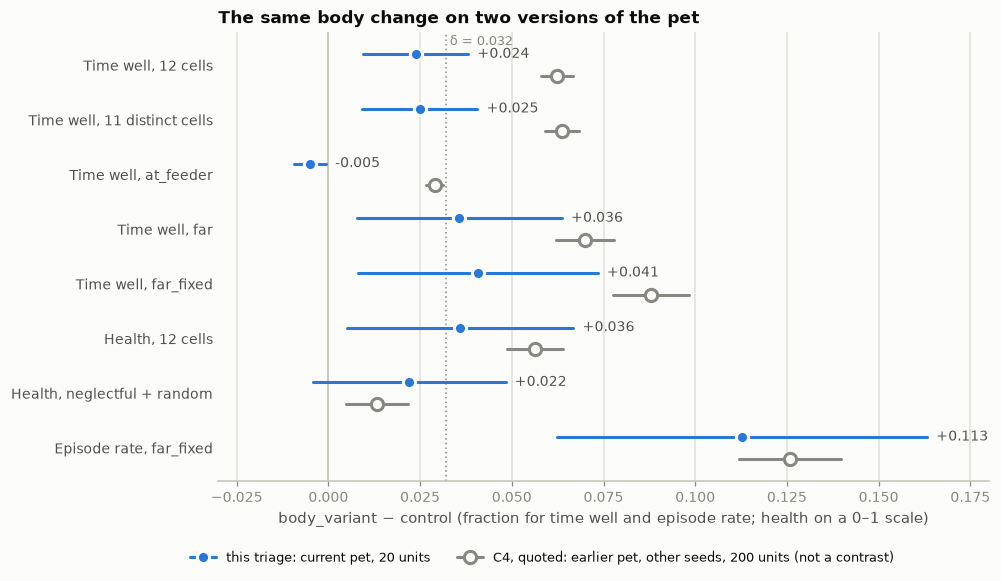

In [6]:
#| label: fig-forest
#| fig-cap: "body_variant − control with 95% CIs. Filled: this triage (current pet, 20 units). Hollow: the earlier study's values (earlier pet, other seeds, 200 units), quoted from the official result; the two are not a contrast. The dotted line marks the plan's margin δ (no external source); the triage applies no rule to it."
#| code-summary: "Forest plot"
#| fig-alt: "Forest plot of body variant minus control for eight measures, each with two marks: this triage (filled) and the earlier study's quoted value (hollow). On time well over 12 cells the triage gives +0.024 [+0.009; +0.038] against +0.062 on the earlier pet; at the feeder the triage is slightly negative (-0.005). Seven of the eight triage estimates are smaller than the earlier values, with wider intervals. A dotted line marks the plan's margin δ = 0.032."
rows = [("Time well, 12 cells", "time_well|12_cells"), ("Time well, 11 distinct cells", "time_well|11_cells"),
        ("Time well, at_feeder", "time_well|at_feeder"), ("Time well, far", "time_well|far"),
        ("Time well, far_fixed", "time_well|far_fixed"), ("Health, 12 cells", "health_d8_14|12_cells"),
        ("Health, neglectful + random", "health_d8_14|neglectful_and_random"),
        ("Episode rate, far_fixed", "episode_rate|far_fixed")]
fig, ax = plt.subplots(figsize=(9.2, 5.4))
off = 0.2
for i, (lab, n) in enumerate(rows):
    r, c = E[n], C4[n]
    ax.plot([c["ci_low"], c["ci_high"]], [i + off] * 2, color=style.CONTEXT, lw=2, zorder=2)
    ax.plot(c["mean"], i + off, "o", ms=8, mfc=style.SURFACE, mec=style.CONTEXT, mew=2, zorder=3)
    ax.plot([r["ci_low"], r["ci_high"]], [i - off] * 2, color=style.ACCENT, lw=2, zorder=3)
    ax.plot(r["mean"], i - off, "o", ms=8, color=style.ACCENT, mec=style.SURFACE, mew=2, zorder=4)
    ax.annotate(f"{r['mean']:+.3f}", (r["ci_high"], i - off), xytext=(6, 0), textcoords="offset points",
                va="center", color=style.INK_2, fontsize=9)
ax.axvline(0, color=style.BASELINE, lw=1, zorder=1)
ax.axvline(tr.MARGIN, color=style.MUTED, lw=1, ls=(0, (1, 2)), zorder=1)
ax.text(tr.MARGIN, -0.55, f" δ = {tr.MARGIN}", color=style.MUTED, fontsize=8.5, va="top")
ax.plot([], [], "o-", color=style.ACCENT, ms=8, mec=style.SURFACE, mew=2, label="this triage: current pet, 20 units")
ax.plot([], [], "o-", color=style.CONTEXT, ms=8, mfc=style.SURFACE, mew=2,
        label="C4, quoted: earlier pet, other seeds, 200 units (not a contrast)")
ax.legend(loc="upper center", bbox_to_anchor=(0.42, -0.13), ncol=2, fontsize=8.5)
ax.set_yticks(range(len(rows)), [lab for lab, _ in rows])
ax.set_ylim(len(rows) - 0.4, -0.6)
ax.set_xlim(-0.03, 0.18)
ax.grid(axis="y", visible=False)
ax.set_xlabel("body_variant − control (fraction for time well and episode rate; health on a 0–1 scale)")
ax.set_title("The same body change on two versions of the pet")
fig.tight_layout()
plt.show()

In [7]:
#| label: vs-margin
eom = REF["effect_over_margin"]["time_well|12_cells"]
assert abs(t12["mean"] / tr.MARGIN - eom) <= 1e-9
lo_d, hi_d = t12["ci_low"] / tr.MARGIN, t12["ci_high"] / tr.MARGIN
say(f'''**Read as sizes, not as a verdict.** Over the 12 cells the estimate is {q(t12)}, which is
**{eom:.2f} δ**, with the interval running from {lo_d:.2f} δ to {hi_d:.2f} δ (δ = {tr.MARGIN}, the plan's margin,
which has no external source). Over the 11 distinct cells it is {q(E['time_well|11_cells'])}. With
{tr.N_UNITS} units the half-width of the 12-cell interval is {(t12['ci_high'] - t12['ci_low']) / 2:.3f}: wide enough
that the triage cannot say whether the effect is above or below δ, but narrow enough for what the addendum asked of
it: to tell an effect of the earlier pet's size from a much smaller one.''')

**Read as sizes, not as a verdict.** Over the 12 cells the estimate is +0.024 [+0.009; +0.038], which is
**0.74 δ**, with the interval running from 0.30 δ to 1.19 δ (δ = 0.032, the plan's margin,
which has no external source). Over the 11 distinct cells it is +0.025 [+0.009; +0.041]. With
20 units the half-width of the 12-cell interval is 0.014: wide enough
that the triage cannot say whether the effect is above or below δ, but narrow enough for what the addendum asked of
it: to tell an effect of the earlier pet's size from a much smaller one.

## 6. Why it shrank? What the official result describes

The triage cannot test why the effect is smaller; it was not designed to. What follows is not an explanation: it is what the official result describes alongside the estimates, without a reading, with each number recomputed. The plan had written the same points before the triage, as the grounds of its prediction. Nothing here is a decomposition of the gap between the two studies.

In [8]:
#| label: why
#| code-summary: "Starting level, exhaustion, the ceiling of the measure, the sign at the feeder"
G = REF["by_group"]
lev = {m: tr.estimate(m, "12_cells") for m in ("exhaustion", "deprivation", "sleep_frac_ticks", "meals_per_day",
                                                "kicks", "play_decisions")}
for m, r in lev.items():
    check(r, G["12_cells"][m], f"12 cells {m}")
near = tr.estimate(f"CAST(time_well > {tr.NEAR_CEILING} AS DOUBLE)", "12_cells")
check(near, G["12_cells"]["share_time_well_above_0_99"], "share above 0.99")
cell = {c: tr.estimate("time_well", c) for c in REF["time_well_by_cell"]}
for c, r in cell.items():
    check(r, REF["time_well_by_cell"][c], f"cell {c}")
feeding = [cell[f"{o}|at_feeder"]["control"] for o in ("attentive", "inconsistent")]
assert feeding[0] == feeding[1]
feeder, c4_feeder = E["time_well|at_feeder"], C4["time_well|at_feeder"]
assert t12["control"] > c12["control"] and lev["exhaustion"]["ci_high"] < 0
assert feeder["ci_high"] < 0 < c4_feeder["ci_low"]
say(f'''
- **The current pet already starts higher.** Its time well without the variant is **{t12['control']:.3f}**; the earlier
  pet's was {c12['control']:.3f}. There is less room to gain.
- **It has little exhaustion ({lev['exhaustion']['control']:.3f} of its decisions).** The variant still lowers
  exhaustion over the 12 cells ({q(lev['exhaustion'])}), from a level that is already low. The official
  result compares this with the earlier pet's level; that level is not part of the comparison values the result
  publishes, so it is not quoted here.
- **The measure hits its ceiling.** With the owners who feed at the feeder (`attentive` and `inconsistent`), the
  current pet's time well is already **{feeding[0]:.3f}** without the variant. Over the 12 cells,
  **{near['control']:.0%}** of the control lives and **{near['body_variant']:.0%}** of the variant lives are above
  {tr.NEAR_CEILING}.
- **At the feeder the sign flips.** There the triage gives {q(feeder)}, small and negative; the earlier pet's value
  there was {q(c4_feeder)}.
''')


- **The current pet already starts higher.** Its time well without the variant is **0.728**; the earlier
  pet's was 0.633. There is less room to gain.
- **It has little exhaustion (0.115 of its decisions).** The variant still lowers
  exhaustion over the 12 cells (-0.046 [-0.054; -0.038]), from a level that is already low. The official
  result compares this with the earlier pet's level; that level is not part of the comparison values the result
  publishes, so it is not quoted here.
- **The measure hits its ceiling.** With the owners who feed at the feeder (`attentive` and `inconsistent`), the
  current pet's time well is already **0.983** without the variant. Over the 12 cells,
  **19%** of the control lives and **28%** of the variant lives are above
  0.99.
- **At the feeder the sign flips.** There the triage gives -0.005 [-0.009; -0.001], small and negative; the earlier pet's value
  there was +0.029 [+0.027; +0.031].


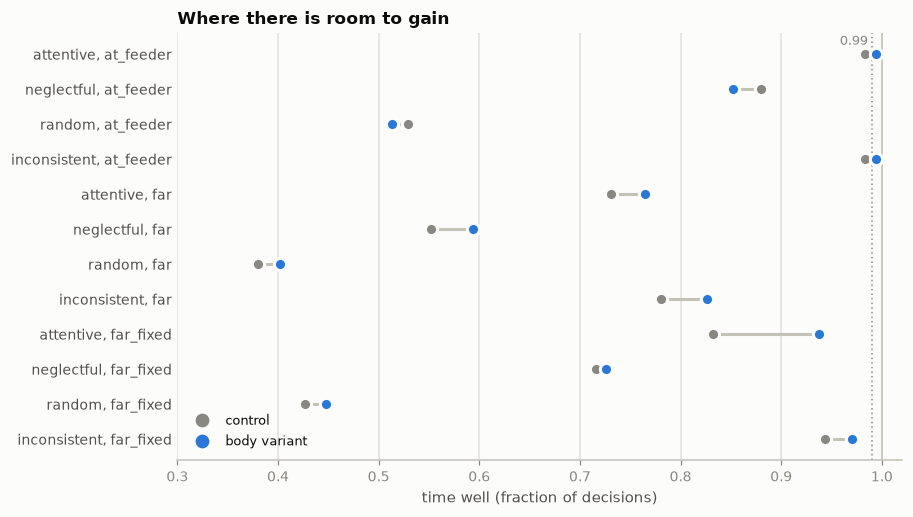

In [9]:
#| label: fig-cells
#| fig-cap: "Time well by cell, mean over the 20 units, without (gray) and with (blue) the body variant. Descriptive. At the feeder, the attentive and inconsistent rows are the same lives."
#| code-summary: "Chart: time well by cell"
#| fig-alt: "Dot chart of time well in each of the 12 owner type × place cells, control in gray and body variant in blue. With the attentive and inconsistent owners at the feeder both arms are already close to 1 (0.983 without the variant), next to the dotted 0.99 line, so there is little room to gain; the larger gains are in far and far_fixed cells."
cells_order = [f"{o}|{p}" for p in tr.PLACES for o in tr.OWNERS]
fig, ax = plt.subplots(figsize=(8.4, 4.8))
for i, c in enumerate(cells_order):
    r = cell[c]
    ax.plot([r["control"], r["body_variant"]], [i, i], color=style.BASELINE, lw=2, zorder=2)
    ax.plot(r["control"], i, "o", ms=8, color=style.CONTEXT, mec=style.SURFACE, mew=2, zorder=3)
    ax.plot(r["body_variant"], i, "o", ms=8, color=style.ACCENT, mec=style.SURFACE, mew=2, zorder=4)
ax.axvline(tr.NEAR_CEILING, color=style.MUTED, lw=1, ls=(0, (1, 2)))
ax.axvline(1, color=style.BASELINE, lw=1)
ax.text(tr.NEAR_CEILING, -0.55, f"{tr.NEAR_CEILING} ", ha="right", va="top", color=style.MUTED, fontsize=8.5)
ax.plot([], [], "o", color=style.CONTEXT, ms=8, label="control")
ax.plot([], [], "o", color=style.ACCENT, ms=8, label="body variant")
ax.legend(loc="lower left", fontsize=8.5)
ax.set_yticks(range(len(cells_order)), [c.replace("|", ", ") for c in cells_order])
ax.set_ylim(len(cells_order) - 0.4, -0.6)
ax.set_xlim(0.3, 1.02)
ax.grid(axis="y", visible=False)
ax.set_xlabel("time well (fraction of decisions)")
ax.set_title("Where there is room to gain")
fig.tight_layout()
plt.show()

In [10]:
#| label: by-place
#| code-summary: "The descriptive table by place (official, recomputed)"
SHOW = {"time_well_d8_14": "time well, days 8–14", "deprivation": "deprivation, days 1–14",
        "exhaustion": "exhaustion, days 1–14", "health_d8_14": "health, days 8–14", "episode_rate": "episode rate",
        "meals_per_day": "meals per day", "sleep_frac_ticks": "share of time asleep", "kicks": "ball kicks per life",
        "play_decisions": "'play' decisions per life"}
rows_ = []
for m, lab in SHOW.items():
    row = {"body_variant − control [95% CI]": lab}
    for g in ("at_feeder", "far", "far_fixed", "12_cells"):
        r = tr.estimate(m, g)
        check(r, G[g][m], f"{g} {m}")
        d = 1 if m in ("meals_per_day", "kicks", "play_decisions") else 3
        row[g.replace("_cells", " cells")] = tr.fmt(r, d)
    rows_.append(row)
show(pd.DataFrame(rows_))
k = lev["kicks"]
assert lev["sleep_frac_ticks"]["ci_high"] < 0 and lev["meals_per_day"]["ci_low"] > 0
assert k["ci_high"] < 0 and lev["play_decisions"]["ci_low"] > 0
say(f'''As with the earlier pet, the variant pet sleeps less and eats more. One thing differs: it kicks the ball less,
{tr.fmt(k, 1)} kicks per life over the 12 cells (from {k['control']:.1f} to {k['body_variant']:.1f}), although it
chooses "play" more often; the earlier pet with the variant kicked more. The episode rate (the share of hunger episodes
the pet closes in time by eating a ripe ration from the owner) rises almost as much as on the earlier pet.''')

body_variant − control [95% CI],at_feeder,far,far_fixed,12 cells
"time well, days 8–14",-0.002 [-0.011; +0.007],+0.059 [+0.008; +0.110],+0.051 [-0.007; +0.110],+0.036 [+0.007; +0.065]
"deprivation, days 1–14",+0.008 [+0.004; +0.012],-0.033 [-0.061; -0.005],-0.038 [-0.070; -0.005],-0.021 [-0.035; -0.007]
"exhaustion, days 1–14",-0.018 [-0.021; -0.015],-0.071 [-0.084; -0.058],-0.049 [-0.066; -0.033],-0.046 [-0.054; -0.038]
"health, days 8–14",-0.008 [-0.013; -0.004],+0.057 [-0.003; +0.116],+0.060 [+0.002; +0.117],+0.036 [+0.005; +0.067]
episode rate,+0.120 [+0.085; +0.155],+0.080 [+0.040; +0.120],+0.113 [+0.062; +0.163],+0.104 [+0.081; +0.127]
meals per day,+0.6 [+0.5; +0.7],+0.3 [+0.2; +0.4],+0.6 [+0.4; +0.7],+0.5 [+0.4; +0.6]
share of time asleep,-0.079 [-0.081; -0.077],-0.090 [-0.093; -0.088],-0.084 [-0.088; -0.080],-0.085 [-0.087; -0.083]
ball kicks per life,-4.6 [-6.5; -2.7],-1.5 [-3.4; +0.4],-2.4 [-4.0; -0.8],-2.8 [-3.8; -1.9]
'play' decisions per life,+5.8 [+3.3; +8.2],+5.8 [+1.7; +10.0],+12.5 [+8.2; +16.8],+8.0 [+5.8; +10.2]


As with the earlier pet, the variant pet sleeps less and eats more. One thing differs: it kicks the ball less,
-2.8 [-3.8; -1.9] kicks per life over the 12 cells (from 22.8 to 19.9), although it
chooses "play" more often; the earlier pet with the variant kicked more. The episode rate (the share of hunger episodes
the pet closes in time by eating a ripe ration from the owner) rises almost as much as on the earlier pet.

## 7. What the triage cannot show

In [11]:
#| label: cannot
wide = E["health_d8_14|neglectful|far"]
drop = E["health_d8_14|random|at_feeder"]
assert drop["ci_high"] < 0
say(f'''
- **No verdict.** {REF['units']} units and no reading rule: the estimates are sizes, not a confirmation or a rejection.
- **Not a contrast with the earlier study.** Different pets, different seeds; the gap between the two estimates has no
  interval.
- **Wide intervals per cell.** Health for the `neglectful` owner in `far` runs from {wide['ci_low']:+.3f} to
  {wide['ci_high']:+.3f}. Health falls for the `random` owner at the feeder ({q(drop)}), as it did on the earlier pet;
  with no rule applied, that is a description, not a failed guard.
- **Nothing about the game itself.** The current pet is simulated in the research code; a few features of the game's
  version are not in that simulation.
- **Nothing about other versions of the body change,** and nothing about two pets living together.
- **Nothing about why the effect shrank,** beyond the description in section 6.
''')


- **No verdict.** 20 units and no reading rule: the estimates are sizes, not a confirmation or a rejection.
- **Not a contrast with the earlier study.** Different pets, different seeds; the gap between the two estimates has no
  interval.
- **Wide intervals per cell.** Health for the `neglectful` owner in `far` runs from -0.045 to
  +0.225. Health falls for the `random` owner at the feeder (-0.030 [-0.047; -0.013]), as it did on the earlier pet;
  with no rule applied, that is a description, not a failed guard.
- **Nothing about the game itself.** The current pet is simulated in the research code; a few features of the game's
  version are not in that simulation.
- **Nothing about other versions of the body change,** and nothing about two pets living together.
- **Nothing about why the effect shrank,** beyond the description in section 6.


## 8. The decision not to run the 200 units

The plan had computed its precision beforehand: with 200 units the 95% interval of the primary measure would be very narrow, so its reading would depend on where the effect falls relative to δ, not on noise. The official result redoes that arithmetic with the triage's own spread:

In [12]:
#| label: precision
hw = tr.half_width(t12["sd"], tr.N_UNITS_PLANNED)
lo, hi = t12["mean"] - hw, t12["mean"] + hw
inside = -tr.MARGIN < lo and hi < tr.MARGIN
assert inside and round(hw, 3) == 0.004 and round(t12["sd"], 3) == 0.031
assert t12["ci_high"] < tr.CUT_PROPOSED and c12["mean"] < tr.CUT_PROPOSED
say(f'''With n = {tr.N_UNITS_PLANNED} and sd = {t12['sd']:.3f}, the half-width would be about **{hw:.3f}**. A true
effect near {t12['mean']:+.3f} would then give an interval of about [{lo:+.3f}; {hi:+.3f}], entirely inside ±δ: the
plan's class "≈ 0", which its rule reads as **"does not confirm"**, even with a positive sign. δ = {tr.MARGIN} has **no
external source**. This is arithmetic with the triage's estimate, not a result.

No cut was applied to the triage. A cut of 2δ = {tr.CUT_PROPOSED:.3f}, to decide whether the 200-unit run would go
ahead, had been proposed before the triage ran and was never decided; the triage's upper limit ({t12['ci_high']:+.3f}) is below it, and so is the earlier pet's own
estimate ({c12['mean']:+.3f}).

The official result laid this arithmetic out for the decision; the decision itself records no reason. The
arithmetic is context, not the motive.

**I closed the question without the run.** The variant stays a switched-off research option, the game's pet stays as
it is, and the plan's prediction ("does not confirm") stays untested. The triage's units are not reused in any later
confirmatory run.''')

With n = 200 and sd = 0.031, the half-width would be about **0.004**. A true
effect near +0.024 would then give an interval of about [+0.020; +0.028], entirely inside ±δ: the
plan's class "≈ 0", which its rule reads as **"does not confirm"**, even with a positive sign. δ = 0.032 has **no
external source**. This is arithmetic with the triage's estimate, not a result.

No cut was applied to the triage. A cut of 2δ = 0.064, to decide whether the 200-unit run would go
ahead, had been proposed before the triage ran and was never decided; the triage's upper limit (+0.038) is below it, and so is the earlier pet's own
estimate (+0.062).

The official result laid this arithmetic out for the decision; the decision itself records no reason. The
arithmetic is context, not the motive.

**I closed the question without the run.** The variant stays a switched-off research option, the game's pet stays as
it is, and the plan's prediction ("does not confirm") stays untested. The triage's units are not reused in any later
confirmatory run.

## Exploratory, after the result

Nothing in this section was in the plan or in the official result. It adds no reading to the triage, which has none, and it does not revisit the decision. It only draws the precision arithmetic of section 8 for every number of units, with the same inputs: the triage's sd of the unit differences on time well (12 cells) and the plan's δ = 0.032, which has no external source.

In [13]:
#| label: precision-curve
#| code-summary: "Half-width and the chance of an interval inside ±δ, for every n"
from casestudy import explore

sd, mu = t12["sd"], t12["mean"]
ns = np.arange(5, 301)
hws = np.array([tr.half_width(sd, n) for n in ns])
hw20, hw200 = tr.half_width(sd, tr.N_UNITS), tr.half_width(sd, tr.N_UNITS_PLANNED)
assert abs(hw20 - (t12["ci_high"] - t12["ci_low"]) / 2) <= 1e-12 and abs(hw200 - hw) <= 1e-15
mus = {"estimate": mu, "lower": t12["ci_low"], "upper": t12["ci_high"]}
LAB = {"estimate": "the triage's estimate", "lower": "its lower limit", "upper": "its upper limit"}
p_in = {k: np.array([explore.prob_ci_inside(v, sd, n, tr.MARGIN) for n in ns]) for k, v in mus.items()}
p200 = {k: explore.prob_ci_inside(v, sd, tr.N_UNITS_PLANNED, tr.MARGIN) for k, v in mus.items()}
p200_sim = explore.simulate_prob_ci_inside(mu, sd, tr.N_UNITS_PLANNED, tr.MARGIN, reps=20_000, seed=20261126)
assert ns[np.argmax(hws < tr.MARGIN)] == 7  # the figure's alt text relies on this
mc_se = np.sqrt(p200_sim * (1 - p200_sim) / 20_000)  # Monte Carlo error of the simulated share
assert abs(p200_sim - p200["estimate"]) < 3 * mc_se and round(mc_se, 3) == 0.001
assert p200["estimate"] > 0.9 and p200["upper"] < 0.01 and p200["lower"] > 0.99
# the sd itself comes from 20 units: its 95% interval (chi-square, 19 df) and the probability at its ends
from scipy import stats as st
df_sd = tr.N_UNITS - 1
sd_lo, sd_hi = sd * np.sqrt(df_sd / st.chi2.ppf(0.975, df_sd)), sd * np.sqrt(df_sd / st.chi2.ppf(0.025, df_sd))
p_sd_lo, p_sd_hi = (explore.prob_ci_inside(mu, s_, tr.N_UNITS_PLANNED, tr.MARGIN) for s_ in (sd_lo, sd_hi))
assert (round(sd_lo, 3), round(sd_hi, 3)) == (0.023, 0.045) and round(p_sd_lo, 3) == 0.999 and round(p_sd_hi, 2) == 0.73
mid = tr.MARGIN - hw200  # where the blue curve's probability crosses one half
assert abs(explore.prob_ci_inside(mid, sd, tr.N_UNITS_PLANNED, tr.MARGIN) - 0.5) < 1e-9 and round(mid, 3) == 0.028
say(f'''**Exploratory, after the result.** With sd = {sd:.3f}, the half-width of the 95% interval is **{hw20:.3f}**
at n = {tr.N_UNITS} (the triage) and **{hw200:.3f}** at n = {tr.N_UNITS_PLANNED} (the run that did not happen).

If the true effect were the triage's estimate ({mu:+.3f}), with the sd fixed at the triage's value ({sd:.3f}), a
{tr.N_UNITS_PLANNED}-unit interval would lie entirely inside ±δ (the plan's class "≈ 0", read as "does not confirm")
with probability **{p200["estimate"]:.3f}** by the normal approximation and **{p200_sim:.3f}** in {20_000:,} simulated
intervals with a fixed seed (Monte Carlo error ±{mc_se:.3f}): ≈ {p200["estimate"]:.2f} by both methods. That sd comes from
only {tr.N_UNITS} units: its own 95% interval runs from about {sd_lo:.3f} to {sd_hi:.3f}, and across it the probability
would run from about {p_sd_lo:.3f} to {p_sd_hi:.2f}. The same arithmetic at the ends of the triage's own interval for
the effect gives {p200["lower"]:.2f} at {mus["lower"]:+.3f} and {p200["upper"]:.2f} at {mus["upper"]:+.3f}: the answer
depends mostly on where the true effect sits, with the turning point (probability one half) near
δ − half-width ≈ {mid:.3f}, not at δ itself; the triage cannot pin that down.

This is arithmetic on the triage's estimate, not a result: the triage has no formal reading, δ has no external source,
and the decision to close the question records no reason; as in section 8, the arithmetic is context, not the
motive.''')

**Exploratory, after the result.** With sd = 0.031, the half-width of the 95% interval is **0.014**
at n = 20 (the triage) and **0.004** at n = 200 (the run that did not happen).

If the true effect were the triage's estimate (+0.024), with the sd fixed at the triage's value (0.031), a
200-unit interval would lie entirely inside ±δ (the plan's class "≈ 0", read as "does not confirm")
with probability **0.966** by the normal approximation and **0.965** in 20,000 simulated
intervals with a fixed seed (Monte Carlo error ±0.001): ≈ 0.97 by both methods. That sd comes from
only 20 units: its own 95% interval runs from about 0.023 to 0.045, and across it the probability
would run from about 0.999 to 0.73. The same arithmetic at the ends of the triage's own interval for
the effect gives 1.00 at +0.009 and 0.00 at +0.038: the answer
depends mostly on where the true effect sits, with the turning point (probability one half) near
δ − half-width ≈ 0.028, not at δ itself; the triage cannot pin that down.

This is arithmetic on the triage's estimate, not a result: the triage has no formal reading, δ has no external source,
and the decision to close the question records no reason; as in section 8, the arithmetic is context, not the
motive.

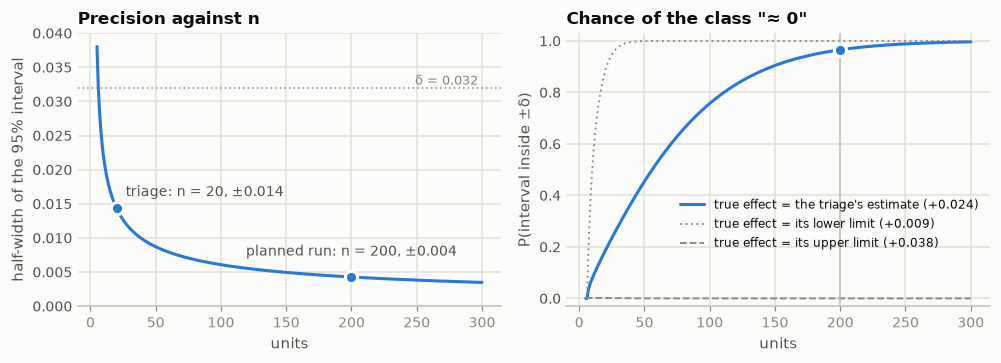

In [14]:
#| label: fig-precision
#| fig-cap: "Exploratory, after the result. Left: half-width of the 95% interval of time well (12 cells) against the number of units, at the triage's sd, with the triage (n = 20) and the planned run (n = 200) marked; the dotted line is δ = 0.032 (no external source). Right: the probability that an interval of n units lies entirely inside ±δ, if the true effect were the triage's estimate (blue) or either end of its interval (gray). Arithmetic, not a result."
#| code-summary: "Chart: precision against n"
#| fig-alt: "Two-panel chart against the number of units, from 5 to 300. Left: the half-width of the 95% interval falls steeply, from about 0.014 at 20 units to about 0.004 at 200, below the dotted δ = 0.032 line from 7 units on. Right: the probability that the interval lies inside ±δ; for a true effect equal to the triage's estimate (+0.024), with the sd fixed at the triage's value, it rises to about 0.97 at 200 units (normal approximation and simulation agree); for the lower end of the triage's interval it approaches 1, for the upper end (+0.038) it stays near 0."
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
ax = axes[0]
ax.plot(ns, hws, color=style.ACCENT)
ax.axhline(tr.MARGIN, color=style.MUTED, lw=1, ls=(0, (1, 2)))
ax.text(300, tr.MARGIN, f"δ = {tr.MARGIN} ", ha="right", va="bottom", color=style.MUTED, fontsize=8.5)
for n, h, lab in ((tr.N_UNITS, hw20, "triage"), (tr.N_UNITS_PLANNED, hw200, "planned run")):
    ax.plot(n, h, "o", ms=8, color=style.ACCENT, mec=style.SURFACE, mew=2, zorder=4)
    ax.annotate(f"{lab}: n = {n}, ±{h:.3f}", (n, h), xytext=(6, 8) if n < 100 else (0, 14), textcoords="offset points",
                ha="left" if n < 100 else "center", color=style.INK_2, fontsize=9)
ax.set_ylim(0, 0.04)
ax.grid(axis="y", visible=True)
ax.set_xlabel("units")
ax.set_ylabel("half-width of the 95% interval")
ax.set_title("Precision against n")
ax = axes[1]
for k, v in p_in.items():
    main = k == "estimate"
    ax.plot(ns, v, color=style.ACCENT if main else style.CONTEXT, lw=2 if main else 1.2,
            ls={"estimate": "-", "lower": (0, (1, 2)), "upper": "--"}[k],
            label=f"true effect = {LAB[k]} ({mus[k]:+.3f})")
ax.axvline(tr.N_UNITS_PLANNED, color=style.BASELINE, lw=1)
ax.plot(tr.N_UNITS_PLANNED, p200["estimate"], "o", ms=8, color=style.ACCENT, mec=style.SURFACE, mew=2, zorder=4)
ax.set_ylim(-0.03, 1.03)
ax.grid(axis="y", visible=True)
ax.set_xlabel("units")
ax.set_ylabel("P(interval inside ±δ)")
ax.set_title("Chance of the class \"≈ 0\"")
ax.legend(loc="center right", bbox_to_anchor=(1, 0.3), fontsize=8)
fig.tight_layout()
plt.show()

## 9. What I would do differently

1. **Decide the go/no-go cut before the triage.** The addendum itself recommended it: a cut chosen after seeing the number is a decision made looking at the number. Here the cut was never decided, and the decision to stop was taken with the estimate in hand.
2. **Give the margin a source.** δ is a judgement call with no external source, and the plan's own precision arithmetic showed that, with 200 units, δ alone would decide the reading. The number that decides should be the best-justified one.
3. **Pick a welfare measure with headroom.** Near the feeder, time well is already close to its maximum, so gains there are invisible by construction. A measure that saturates hides exactly the cells where a change could look neutral or slightly negative.
4. **Re-measure effect sizes whenever the system under test changes.** The earlier estimate was precise, but precise about a pet that no longer exists. A cheap re-measurement on the current version showed that the current estimate is less than half the earlier one (the two are not a contrast).

## 10. Reproduce it

Everything on this site is rebuilt from the published data with one command (Python ≥ 3.12 and [uv](https://docs.astral.sh/uv/); all dependencies, including Quarto, are pinned in `uv.lock`):

```
uv sync
uv run python scripts/reproduce.py
```

It runs the DuckDB integrity checks of both cases, executes every notebook in place (each stops on a failed assertion) and renders the site into `docs/`. The [reproduction appendix](03_reproduce_body_triage.ipynb) recomputes every official estimate and descriptive table of the triage.

In [15]:
#| label: gate
assert len([c for c in CHECKS if "|" in c and not c.startswith("cell")]) == len(REF["estimates"]) == 14
assert len([c for c in CHECKS if c.startswith("cell")]) == 12
say(f"**Gate:** {len(CHECKS)} checks of official values on this page (some values are checked more than once) recomputed and matched "
    f"`body_triage_reference.json` (tolerance 1e-9); the earlier study's values are read from the same file.")

**Gate:** 71 checks of official values on this page (some values are checked more than once) recomputed and matched `body_triage_reference.json` (tolerance 1e-9); the earlier study's values are read from the same file.